### Dashboard Base Code

#### Setup

In [12]:
# Packages
from pathlib import Path
import pandas as pd 
import geopandas as gpd
import seaborn as sns
import re
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
from scipy import stats
from bs4 import BeautifulSoup
import requests

#widget packages
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

In [6]:
# Paths 
project_fldr = Path.cwd().parent
raw_fldr = project_fldr /'Data'/'unprocessed' 
processed_fldr = project_fldr /'Data'/'processed'

In [7]:
# Import cleaned data
pest_water_categorized = pd.read_csv(processed_fldr/'pest_water_cat.csv')
pest_water_categorized.head()

,Pesticide_Name,Water_Year,site_id,mean_concentration_water,mean_pesticide_use,log_mean_pesticide_use,log_mean_concentration_water,Pest_Category
0,"2,4-D",2013,1184000,0.128033,362.3,2.559068,-0.892677,herbicide
1,"2,4-D",2013,1209710,0.075609,80.7,1.906874,-1.121428,herbicide
2,"2,4-D",2013,1349150,0.063613,515.2,2.711976,-1.196458,herbicide
3,"2,4-D",2013,1372043,0.052507,742.3,2.870579,-1.279782,herbicide
4,"2,4-D",2013,1463500,0.061000,419.3,2.622525,-1.214670,herbicide


#### Base Plot

In [21]:
#Seaborn Theme 
sns.set_theme(style='whitegrid', 
              context='notebook', 
              palette= "pastel", 
              font_scale=0.8, 
              rc={
                  "axes.titlesize": 20, 
                  "font.family": "serif"}
 )

In [29]:
# Filtering data

Year = "2013"
Pesticide_Category = "herbicide"

# Subset the data
pest_water_categorized_subset = pest_water_categorized.loc[
    (pest_water_categorized['Water_Year'] == Year) &
    (pest_water_categorized['Pest_Category'] == Pesticide_Category),
]

[Text(0.5, 1.0, 'Average County herbicide Use vs. Average Water Concentration '),
 Text(0.5, 0, 'Logged County herbicide Use, High Estimate  avg(kg)'),
 Text(0, 0.5, 'Logged Water Concentration avg (µg/L)')]

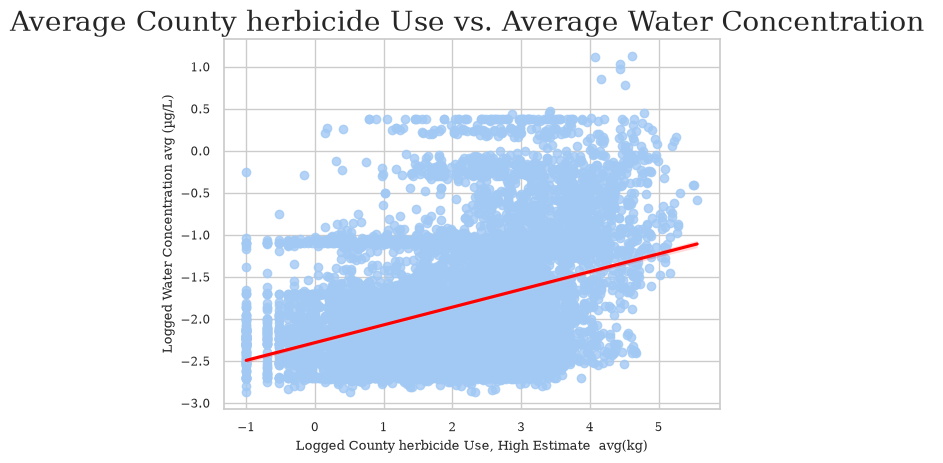

In [30]:
# Plotting data
Lin_reg = sns.regplot(
    data= pest_water_categorized,
    x='log_mean_pesticide_use',
    y='log_mean_concentration_water',
    line_kws={'color': 'red'}

)
Lin_reg.set(
    title=(f'Average County {Pesticide_Category} Use vs. Average Water Concentration '),
    xlabel=(f'Logged County {Pesticide_Category} Use, High Estimate  avg(kg)'),
    ylabel='Logged Water Concentration avg (µg/L)',
)



#### Convert to a function

In [49]:
# Plot as a Function

def plot_pesticide(Year = "2013",
    Pesticide_Category = "herbicide"):
    #Subset
    pest_water_categorized_subset = pest_water_categorized.loc[
    (pest_water_categorized['Water_Year'] == Year) &
    (pest_water_categorized['Pest_Category'] == Pesticide_Category),
    ]
    #Plot
    Lin_reg = sns.regplot(
    data= pest_water_categorized_subset,
    x='log_mean_pesticide_use',
    y='log_mean_concentration_water',
    line_kws={'color': 'red'}, 

    )
    Lin_reg.set(
        title=(f'Average County {Pesticide_Category} Use vs. Average Water Concentration '),
        xlabel=(f'Logged County {Pesticide_Category} Use, High Estimate  avg(kg)'),
        ylabel='Logged Water Concentration avg (µg/L)',
    )
    return Lin_reg


<Axes: title={'center': 'Average County herbicide Use vs. Average Water Concentration '}, xlabel='Logged County herbicide Use, High Estimate  avg(kg)', ylabel='Logged Water Concentration avg (µg/L)'>

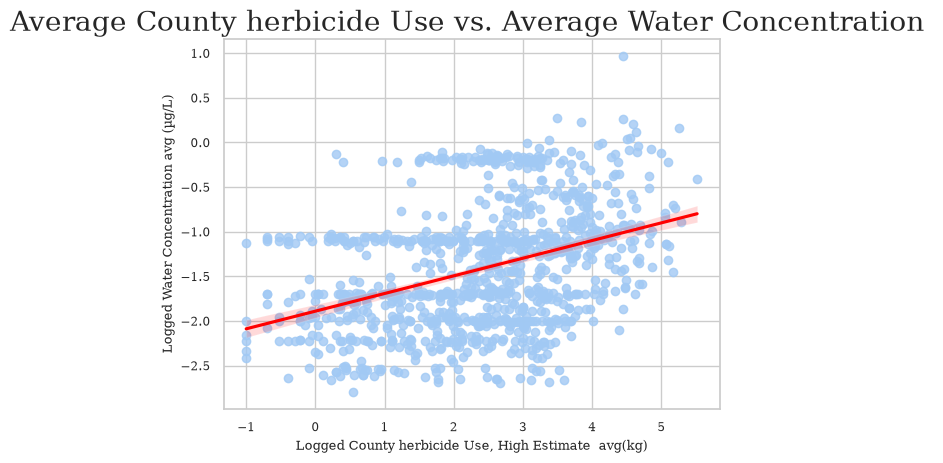

In [62]:
# Apply function
plot_pesticide(Year=2015, Pesticide_Category="herbicide")

#### Widgets

In [73]:
# Create a dropdown widget from Pesticide Category
year_list = pest_water_categorized['Water_Year'].unique()
year_dropdown = widgets.Dropdown(
    options=year_list,
    value=year_list[0],
    description='Year:',
    )

In [74]:
# Create a dropdown widget from Pesticide Category
pest_list = pest_water_categorized['Pest_Category'].unique()
pest_dropdown = widgets.Dropdown(
    options=pest_list,
    value=pest_list[0],
    description='Pesticide:',
    )

In [76]:
# Update the plot
plot_output = widgets.Output()

# Function to update the plot
def update_data_or_plot(change=None):
    #Direct output to the plot_output widget
    with plot_output:
        # Clear the previous plot
        clear_output(wait=True)

        # Generate the new plot
        g = plot_pesticides(Year = year_dropdown.value,
        Pesticide_Category = pest_dropdown.value)

        # Explicitly display the plot
        display(g.figure)
        plt.close(g.figure)

# Attach observers
year_dropdown.observe(update_data_or_plot, names='value')
pest_dropdown.observe(update_data_or_plot, names='value')

# Display the widgets and plot together
display(
    widgets.VBox([
        year_dropdown,
        pest_dropdown,
        plot_output
    ])
)

# Generate the initial plot
update_data_or_plot()